# 01 · Problem definition and data audit
**Project:** Next-day PM2.5 exceedance alerts for Chennai · CS3006

This notebook covers pipeline stages **1 Define → 2 Collect → 3 Clean**.
The cleaning logic lives in `src/` so the notebook and `scripts/01_build_clean_dataset.py`
use exactly the same code.

**Problem (full version in `docs/problem_statement.md`):** for each of four CPCB stations,
predict at the end of day *D* whether the daily mean PM2.5 on day *D+1* will exceed
India's NAAQS 24-hour limit of **60 µg/m³**.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))      # run from the notebooks/ folder

import pandas as pd
from IPython.display import Image, display

from src import config as C
from src.load import load_raw, list_raw_files
from src.health import clean, peer_ratio
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)

## 2 · Data collection
**Source:** Central Pollution Control Board (CPCB), *Data Repository → Raw Data*, frequency
24 h, one CSV per station per year (downloaded Nov 2026). Each file has 12 pollutants and 9
weather channels.

**Why these four stations?** All eight Chennai stations were screened on 2026 data
(coverage, frozen values, agreement with the other stations). Alandur (empty file) and
Ennore (6% coverage) had no data; Velachery repeated filler values (PM2.5 = 17.0 on 29 days);
Royapuram had a frozen PM10 sensor and PM10 computed as a fixed 2.17 × PM2.5. The four
kept stations span the city from the industrial north to the south.

In [2]:
pd.DataFrame(C.STATIONS).T

,name,area,lat,lon
306,Manali,North (industrial),13.1644,80.2588
5365,Kodungaiyur,North,13.1372,80.2478
5361,Arumbakkam,Central,13.0727,80.2109
5363,Perungudi,South,12.9532,80.2357


In [3]:
files = list_raw_files()
print(len(files), "raw files")
raw_all = load_raw()
raw_all.groupby("station")["pm25"].apply(lambda s: s.dropna().index.size).rename("days with PM2.5")

33 raw files


station
Arumbakkam     2010
Kodungaiyur    1947
Manali         2726
Perungudi      2109
Name: days with PM2.5, dtype: int64

### First audit (before changing anything)
The slides' audit checklist: shape, dtypes, share missing, duplicates, impossible values.

In [4]:
first_day = raw_all.dropna(subset=["pm25"]).groupby("station")["date"].min()
print("First day with PM2.5 per station:\n", first_day, "\n")
raw = raw_all[raw_all["date"] >= C.STUDY_START].reset_index(drop=True)
print("Study window shape:", raw.shape)
print("Duplicate (station, date) rows dropped while loading:", raw_all.attrs["duplicates_dropped"])
raw[C.POLLUTANTS + C.STATION_WEATHER].isna().mean().sort_values(ascending=False).round(3)

First day with PM2.5 per station:
 station
Arumbakkam    2020-11-07
Kodungaiyur   2020-11-07
Manali        2019-01-01
Perungudi     2020-12-17
Name: date, dtype: datetime64[us] 

Study window shape: (8576, 27)
Duplicate (station, date) rows dropped while loading: 0


temp     0.898
bp       0.329
ozone    0.303
co       0.284
rf       0.284
wd       0.206
nh3      0.080
nox      0.070
no2      0.069
no       0.068
pm25     0.066
rh       0.059
pm10     0.057
sr       0.053
so2      0.053
ws       0.043
dtype: float64

### Data types: what the raw files contain and how they were converted

In [5]:
one_file = pd.read_csv(files[0][0])
print("Raw file as read by pandas:", one_file.dtypes.value_counts().to_dict())
print("Example column names (units are inside the names):", list(one_file.columns[:4]))
print("\nAfter src/load.py:")
raw[["date", "station_id", "station", "pm25", "co", "nox"]].dtypes

Raw file as read by pandas: {dtype('float64'): 24, <StringDtype(storage='python', na_value=nan)>: 1}
Example column names (units are inside the names): ['Timestamp', 'PM2.5 (µg/m³)', 'PM10 (µg/m³)', 'NO (µg/m³)']

After src/load.py:


date          datetime64[us]
station_id             int64
station                  str
pm25                 float64
co                   float64
nox                  float64
dtype: object

**Type handling and why**
* `Timestamp` arrives as **text**. It is parsed to a real date and normalised to midnight, so
  that days can be compared, sorted and shifted (D → D+1).
* Pollutant columns are already numbers (`float64`); missing readings are written as `NA` or
  blank in the CPCB files and are read as `NaN`, never as 0.
* **Units are kept in mind, not converted:** most pollutants are µg/m³, but CO is mg/m³ and NOx
  is ppb. The short names (`co`, `nox`) are set in `config.COLUMN_MAP`, and their valid ranges in
  `config.VALID_RANGE` use the matching unit.
* If CPCB ever adds an unknown column, `load.py` **stops with an error** instead of silently
  ignoring it.
* Every station gets a **complete daily calendar**: a missing day becomes an explicit row of
  `NaN`, not a silently absent row. That is what makes "tomorrow = next row" safe later.

In [6]:
raw[C.POLLUTANTS + ["rh", "ws", "rf"]].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
pm25,8013.0,27.7,20.8,1.0,14.4,21.5,34.5,397.1
pm10,8091.0,70.4,41.6,1.0,44.2,61.9,88.4,710.6
no,7990.0,5.2,4.7,0.3,2.3,3.9,7.0,101.4
no2,7987.0,10.4,6.1,0.1,5.9,9.8,14.2,108.3
nox,7974.0,11.8,8.3,0.0,6.2,9.9,15.9,117.8
nh3,7890.0,18.9,14.1,0.1,9.7,15.6,23.8,168.8
so2,8120.0,7.4,7.3,0.1,3.3,4.7,9.8,108.8
co,6137.0,0.8,0.5,0.0,0.5,0.6,0.9,7.1
ozone,5974.0,19.7,14.2,0.0,10.0,15.7,28.3,240.6
rh,8071.0,76.1,9.7,1.2,69.3,74.1,81.2,99.7


**What the audit already shows**
* Three stations only start in Nov-Dec 2020, which is why the study starts on 2021-01-01.
* `rf` (rainfall) is almost always 0. Chennai gets heavy north-east monsoon rain in
  Oct-Dec, so the gauges are not working → weather comes from Open-Meteo instead
  (`scripts/00_fetch_weather.py`).
* `temp` is missing for 90% of days at these stations.
* PM2.5 has a long right tail (max >> 75th percentile), which is the exceedance days we care about.

## 3 · Cleaning: sensor-health rules
Each rule targets one known way a CPCB sensor fails. Thresholds are in `src/config.py`.

| Rule | What it catches | Action |
|---|---|---|
| out_of_range | physically impossible values (e.g. RH > 100%) | set NaN |
| pm25_gt_pm10 | PM2.5 > 1.05 × PM10 (PM2.5 is *part of* PM10) | set both NaN |
| stuck_value | ≥ 3 identical daily means in a row (frozen output) | keep first, NaN the repeats |
| flatline | 14-day coefficient of variation < 2% (sensor stops responding) | set NaN |
| peer_drift | 90-day station ÷ median-of-others outside 0.6-1.67 | **flag only**, then review |
| manual exclusion | flagged periods confirmed by a second, independent signal | set NaN, reason logged |

In [7]:
cleaned, audit, drift, spikes, summary = clean(raw)
summary.assign(pct_removed=(summary.removed / summary.valid_before * 100).round(1))

,valid_before,valid_after,removed,pct_removed
pm25,8013,6833,1180,14.7
pm10,8091,8034,57,0.7
no,7990,7416,574,7.2
no2,7987,7136,851,10.7
nox,7974,7071,903,11.3
nh3,7890,6790,1100,13.9
so2,8120,7966,154,1.9
co,6137,5847,290,4.7
ozone,5974,5192,782,13.1
temp,879,563,316,35.9


In [8]:
audit.pivot_table(index=["rule", "column"], columns="station", values="values_removed",
                  aggfunc="sum").fillna(0).astype(int)

station                           Arumbakkam  Kodungaiyur  Manali  Perungudi
rule                   column                                               
flatline               co                  0          106      11          0
                       nh3                 0          127     928         17
                       no                  9          184     323         16
                       no2               131          180     516         12
                       nox               130          210     545          0
                       ozone               0          518     200         45
                       pm10                0            0      29          0
                       pm25                0            0       1          0
                       rh                 92         1988      22        165
                       so2                 0          106      19          0
                       sr                  0            0      64          0
                       temp               68           81      76         91
                       ws                  0            0       0         27
manual_drift_exclusion pm10                0           12       0          0
                       pm25                0          986     176          0
out_of_range           rh                  3            2       0          0
pm25_gt_pm10           pm25+pm10           2            2       8          2
stuck_value            co                  0          104      16         53
                       nh3                25            0       3          0
                       no                  6            2      34          0
                       no2                 6            0       6          0
                       nox                 4            0      12          2
                       ozone               0            0      19          0
                       pm10                0            0       2          0
                       pm25                0            0       3          0
                       rh                  2            0       0        390
                       so2                 0            0      29          0
                       sr                  2            0       0          0
                       wd                168            0       0          0
                       ws                164          148       2        208

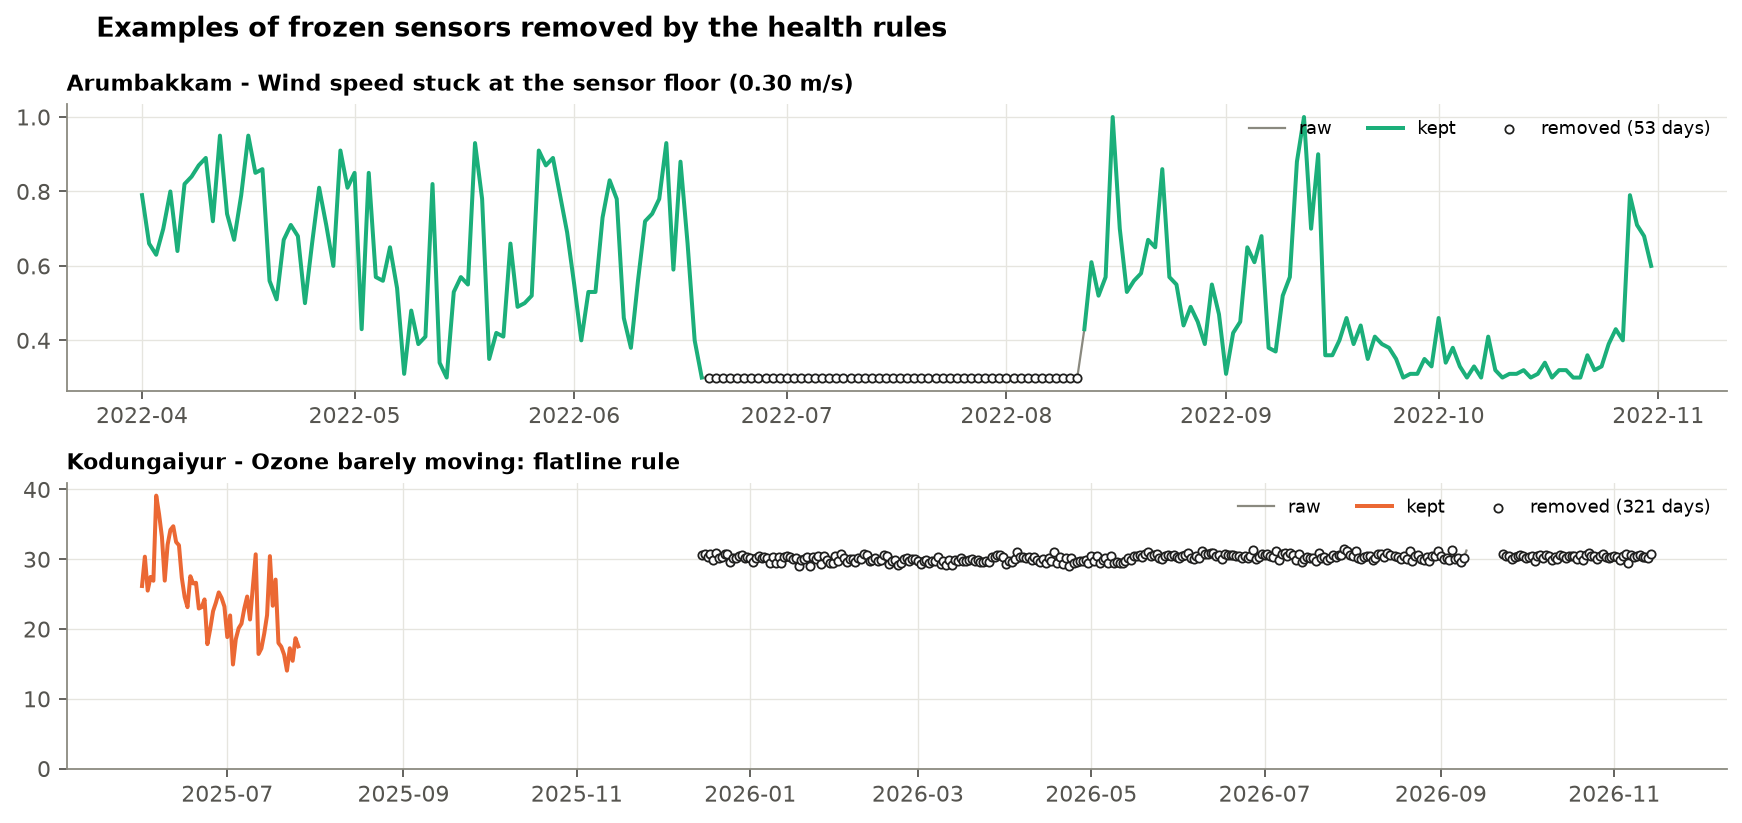

In [9]:
display(Image(str(C.FIG_DIR / "fig04_stuck_sensor_examples.png")))

### Peer check: catching slow calibration drift
All four stations sit in the same city under the same weather, so a healthy sensor's
reading divided by its neighbours' median stays roughly steady. Drift shows as a slow slide.

In [10]:
drift

,station,start,end,days,min_ratio,max_ratio
0,Kodungaiyur,2022-10-08,2023-03-20,164,0.48,0.60
1,Kodungaiyur,2023-10-16,2024-03-20,157,0.44,0.60
2,Kodungaiyur,2024-10-05,2025-02-28,147,0.30,0.60
3,Manali,2023-08-29,2023-09-05,8,1.69,1.71
4,Manali,2023-09-16,2023-09-16,1,1.71,1.71
5,Manali,2023-09-23,2023-09-25,3,1.67,1.71
6,Manali,2024-04-11,2024-08-08,120,1.70,2.95
7,Perungudi,2021-06-11,2021-06-22,12,0.60,0.60
8,Perungudi,2021-06-27,2021-10-16,112,0.50,0.60
9,Perungudi,2026-08-30,2026-09-02,4,0.56,0.60


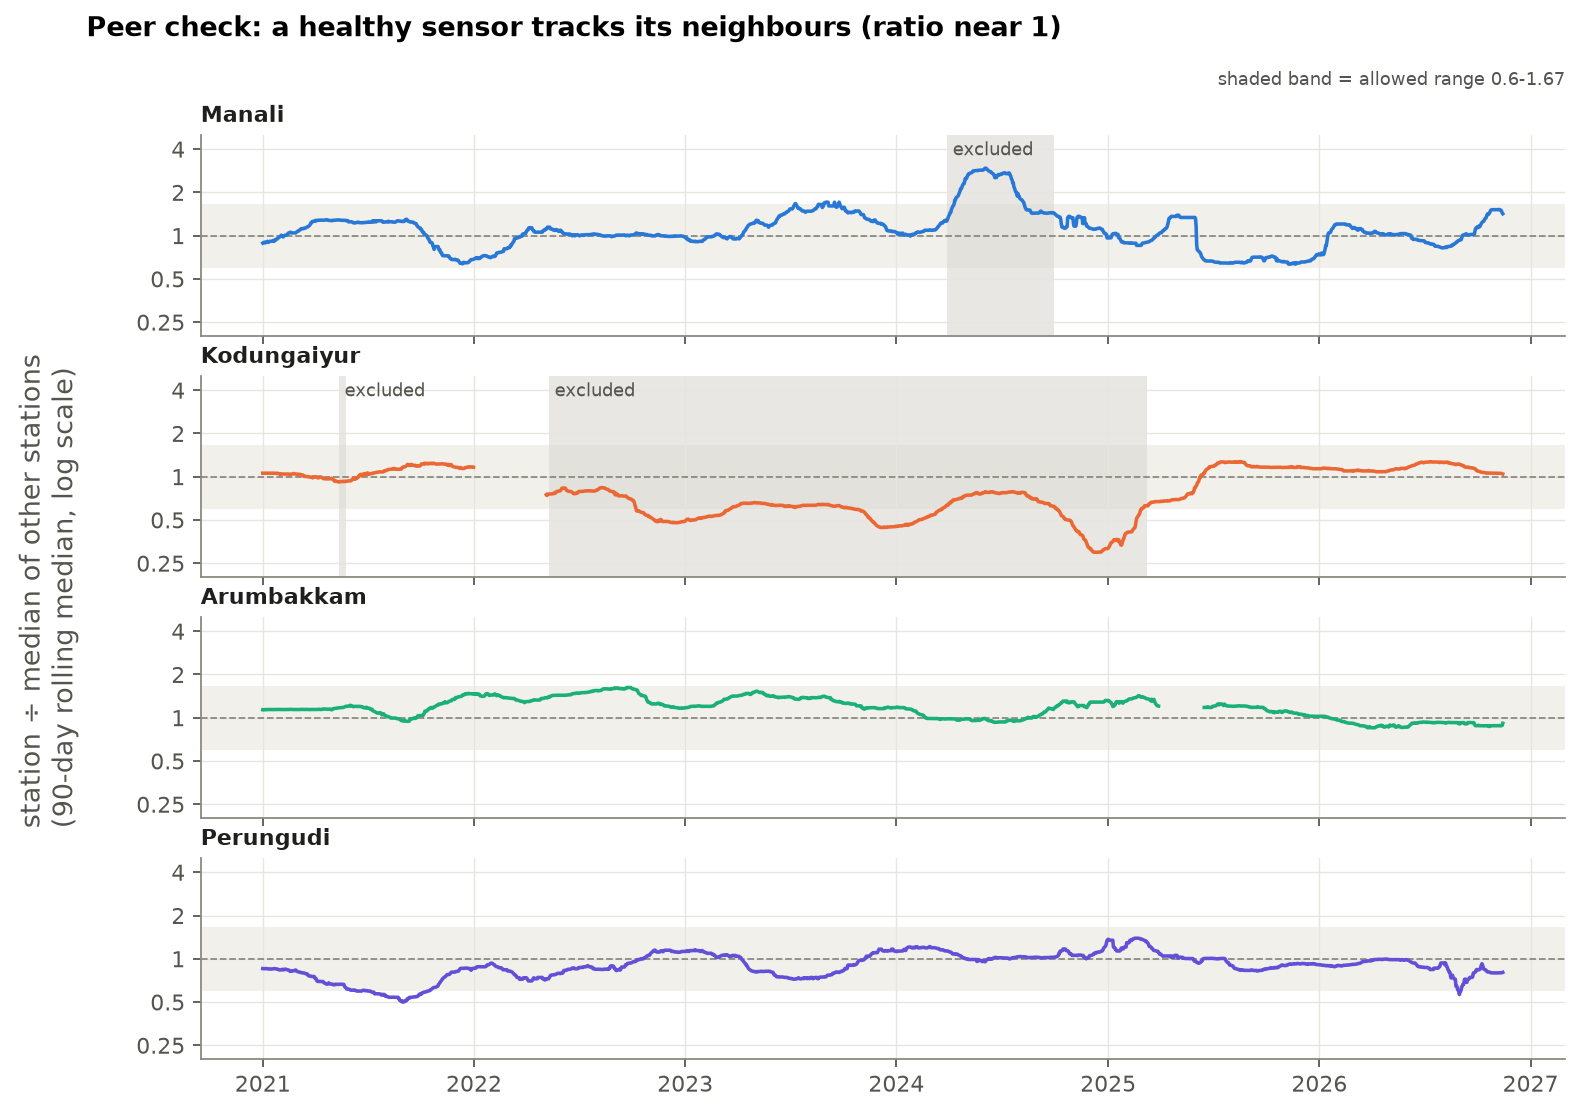

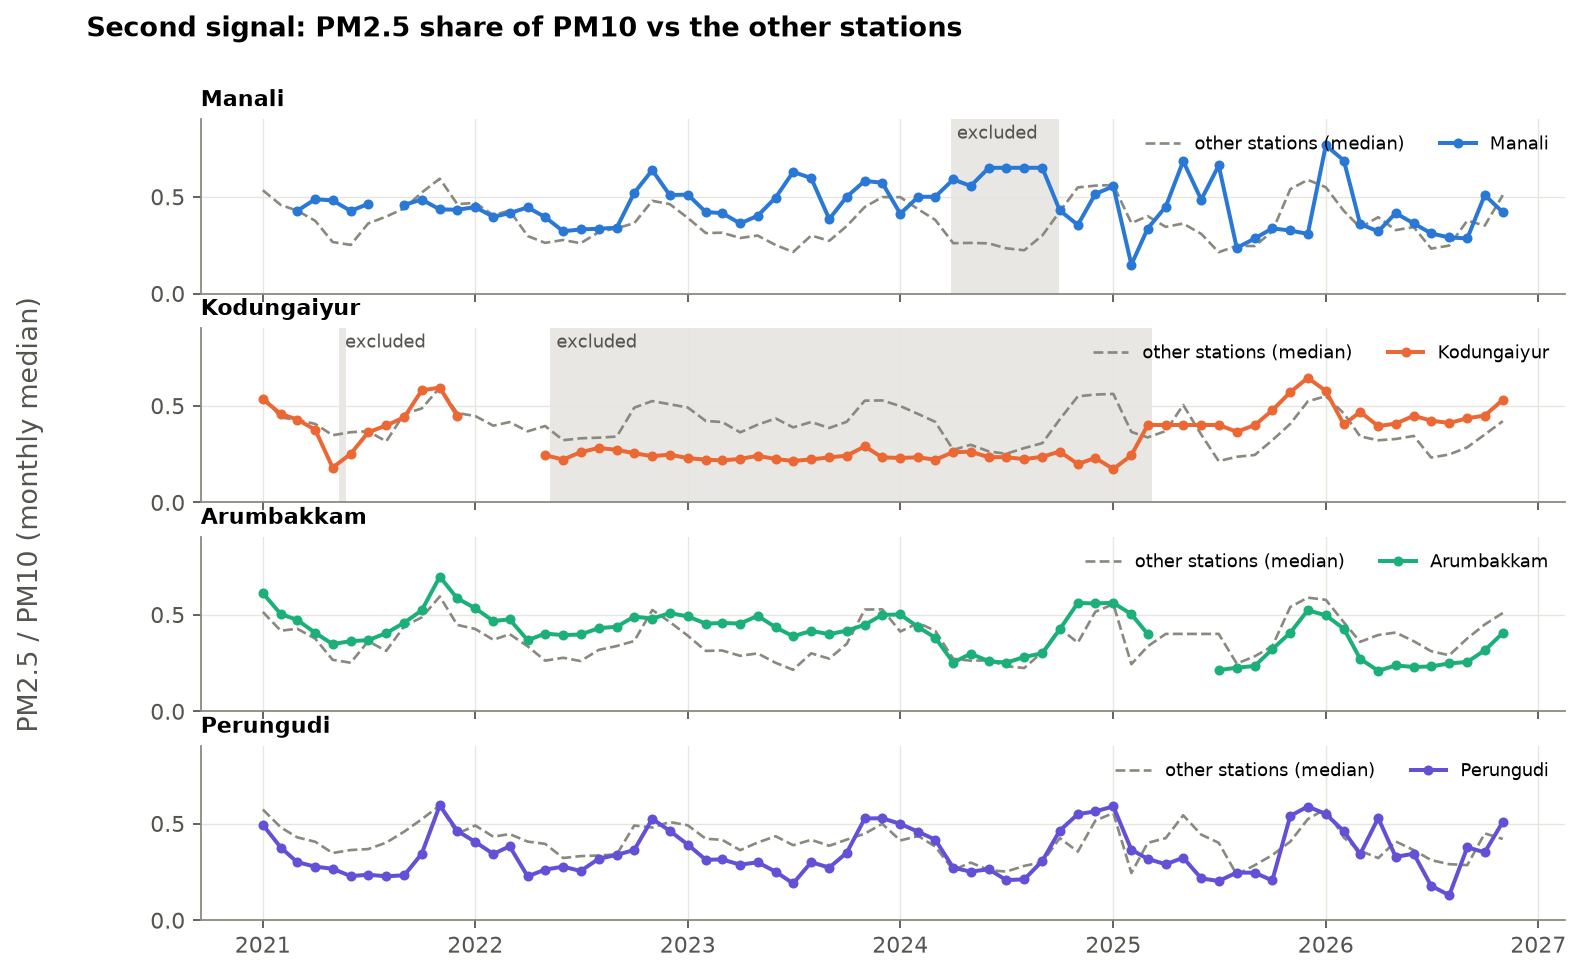

In [11]:
display(Image(str(C.FIG_DIR / "fig02_peer_ratio_drift.png")))
display(Image(str(C.FIG_DIR / "fig03_pm25_pm10_ratio.png")))

**Decision rule:** a period is removed only when a second, independent signal agrees.
Here that second signal is the station's PM2.5/PM10 ratio compared with the others.
* **Kodungaiyur 2022-05 → 2025-03:** peer ratio falls to 0.3-0.8 *and* PM2.5/PM10 is flat at
  ~0.22 while its PM10 stays normal → the PM2.5 instrument under-read. It recovers right
  after a maintenance gap (20 Feb - 9 Mar 2025). Removed.
* **Manali 2024-03-28 → 2024-09-30:** peer ratio 2-4 *and* PM2.5/PM10 = 0.65 vs 0.25 elsewhere
  → over-reading. Removed.
* **Perungudi mid-2021:** ratio 0.5-0.6 but no second signal and no step change. Kept.

In [12]:
display(pd.DataFrame(C.MANUAL_EXCLUSIONS))
display(pd.DataFrame(C.REVIEWED_AND_KEPT))

,station_id,columns,start,end,reason
0,5365,"[pm25, pm10]",2021-05-12,2021-05-24,Failing instrument just before a months-long o...
1,5365,[pm25],2022-05-10,2025-03-09,Calibration drift: PM2.5 falls to 0.3-0.8x the...
2,306,[pm25],2024-03-28,2024-09-30,Over-reading after an outage: PM2.5 jumps to 2...


,station,period,why_kept
0,Perungudi,2021-06 .. 2021-10,"Ratio 0.5-0.6, but Perungudi reads low by a si..."
1,Manali,2023-08-29 .. 2023-09-25,"Short (12 days total), ratio just above the li..."
2,Perungudi,2026-08-30 .. 2026-09-02,"4 days at ratio 0.56-0.60, at the edge of the ..."


### Single-station spikes: error or the most interesting event?
Days where one station reads > 3× the others and > 100 µg/m³. These are **kept**:
5 Nov 2021 is the day after Diwali, and short local events (waste fires, crackers)
are real exposure. The model will most likely miss them, and the error analysis will say so.

In [13]:
spikes

,date,station,pm25,others_median
0,2021-11-05,Perungudi,104.2,34.0
1,2025-12-03,Arumbakkam,206.0,12.4
2,2026-07-12,Perungudi,131.7,23.5
3,2026-07-13,Perungudi,167.4,21.3
4,2026-09-05,Perungudi,155.6,25.9
5,2026-09-06,Perungudi,106.8,22.2


### Why the textbook outlier rule (IQR) was *not* applied
The slides' IQR rule flags values above Q3 + 1.5 × IQR. What would it do to PM2.5?

In [14]:
pm = cleaned.loc[cleaned.date.dt.year <= 2023, "pm25"].dropna()     # training years only
q1, q3 = pm.quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
flagged = pm > fence
bad = pm > C.NAAQS_PM25_24H
print(f"Q1 = {q1:.1f}, Q3 = {q3:.1f}, upper IQR fence = {fence:.1f} µg/m³")
print(f"Days flagged as 'outliers': {flagged.sum()}  |  of these, days above the 60 limit: {(flagged & bad).sum()}")
print(f"Share of all bad days the IQR rule would delete: {(flagged & bad).sum() / bad.sum():.0%}")

Q1 = 15.2, Q3 = 35.5, upper IQR fence = 66.1 µg/m³
Days flagged as 'outliers': 140  |  of these, days above the 60 limit: 140
Share of all bad days the IQR rule would delete: 65%


**Decision:** the IQR rule is **not** used on PM2.5. Its fence (66 µg/m³) sits just above the
limit, so every day it flags is a bad-air day: it would delete about two-thirds of the days we
are trying to predict. High PM2.5 is the signal, not noise. As the slides put it, an outlier is
either an error or the most interesting event in the data, and only domain knowledge can tell
which. Errors are removed by the **sensor-health rules above** (impossible values, frozen and
flat-lined sensors, PM2.5 > PM10, drift), each with a physical reason, and real extreme days are
kept.

## Result

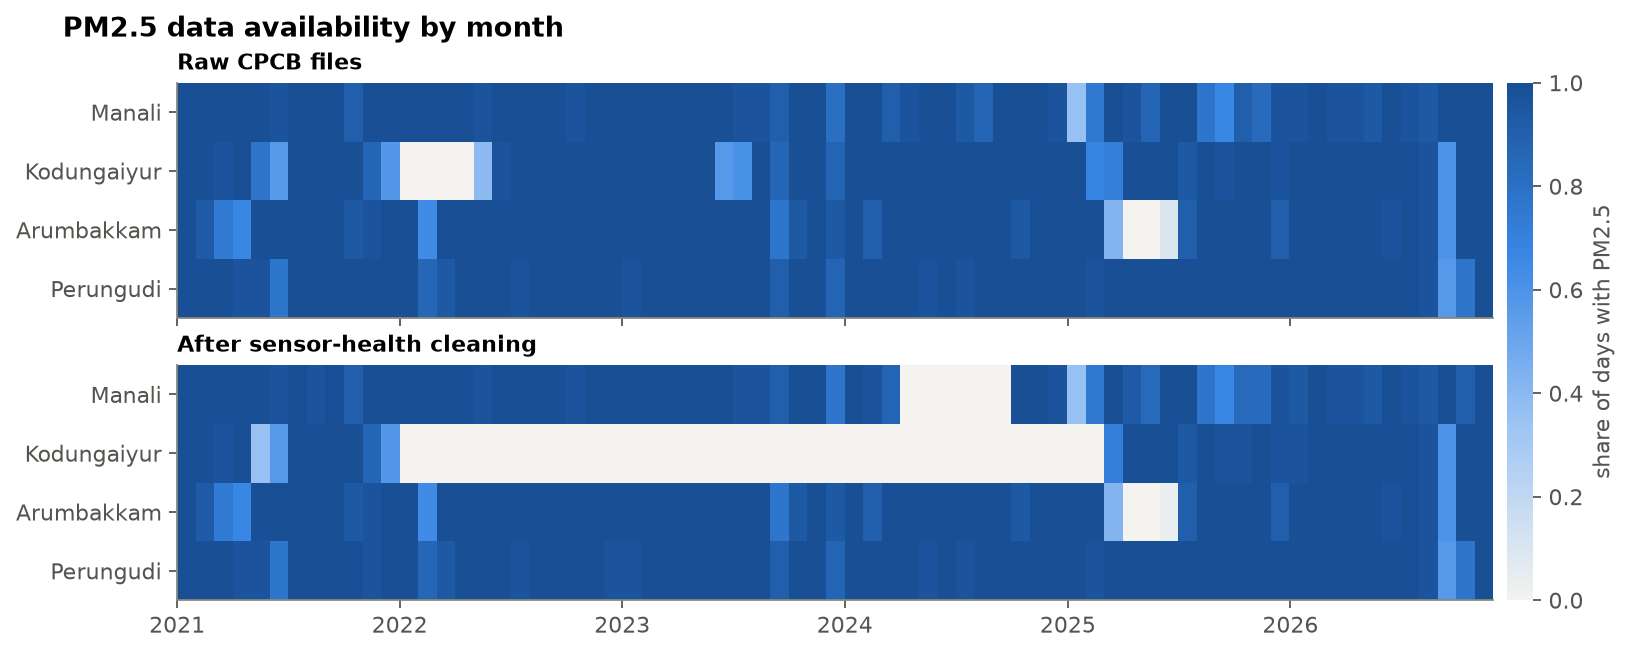

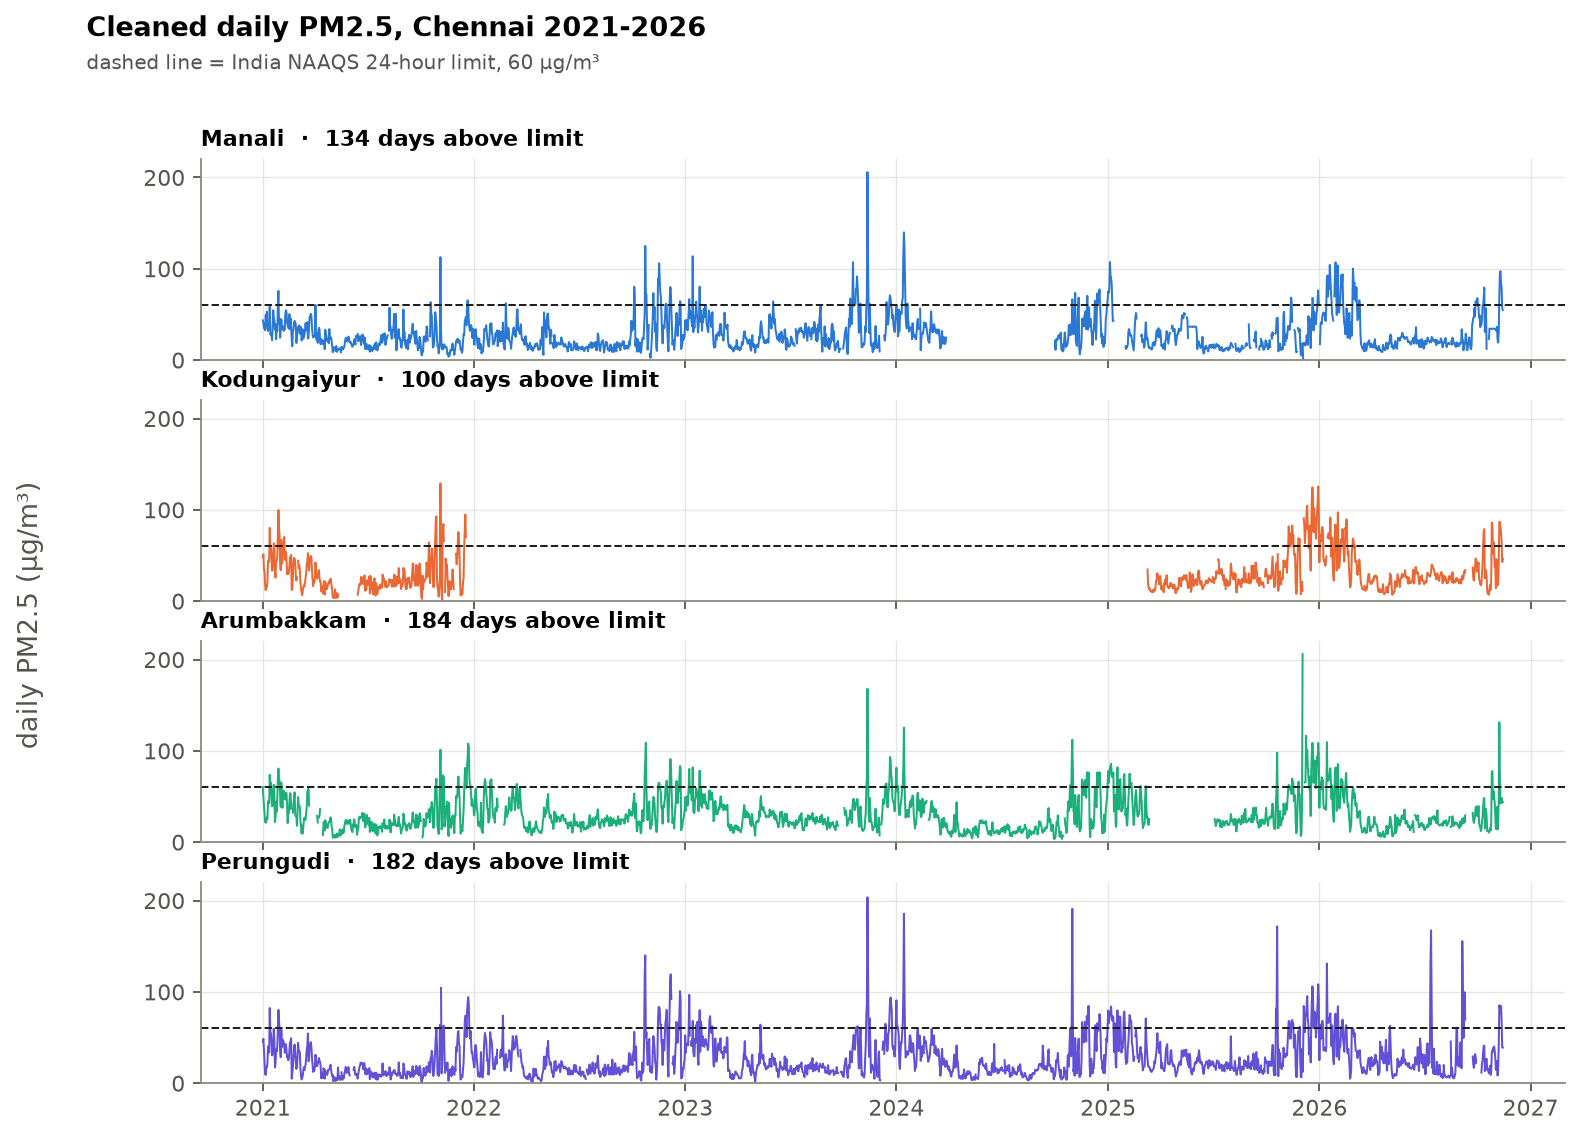

In [15]:
display(Image(str(C.FIG_DIR / "fig01_pm25_availability.png")))
display(Image(str(C.FIG_DIR / "fig05_clean_pm25_timeseries.png")))

In [16]:
d = cleaned.dropna(subset=["pm25"])
balance = (d.assign(year=d.date.dt.year, exceed=d.pm25 > C.NAAQS_PM25_24H)
             .groupby("year").agg(days=("exceed", "size"), exceed_days=("exceed", "sum"),
                                  exceed_rate=("exceed", "mean")))
balance.round(3)

,days,exceed_days,exceed_rate
year,,,
2021,1371,75,0.055
2022,1075,67,0.062
2023,1064,74,0.070
2024,902,76,0.084
2025,1210,157,0.130
2026,1211,151,0.125


**Takeaways for the next stages**
* ~6,800 usable station-days of PM2.5 after removing 14.7% as sensor faults.
* Classes are imbalanced: 5.5-8.4% of days exceed the limit in 2021-2024, rising to ~13% in
  2025-2026. The test year has twice the training rate, which is a data-drift risk to examine.
* Station weather is unreliable → use Open-Meteo weather (next notebook).

**Next:** `02_eda.ipynb`: seasonality, persistence, weather relationships and hypothesis
tests on the training years. Feature building follows in `03_features.ipynb`.